# Notebook 14 — CVaR exact trên choice

Câu hỏi: tối ưu **10% khối lượng xác suất có năng lượng thấp nhất** có tăng xác suất placement tối ưu so với tối ưu năng lượng trung bình ở notebook 13 không?

Chạy **2 lượt CVaR mới**, từ common và alternative. Giữ p=1, penalty (3,3), mixer X, max_abs, COBYLA/rhobeg/tol, maxiter=200 và 1.024 shots cuối. Hàm CVaR dùng phân phối statevector lý tưởng; không có nhiễu shots trong tối ưu. Đây là thí nghiệm simulator, chưa phải một lượt QPU.

CVaR thấp không tự bảo đảm placement tốt hơn: nó vẫn dựa trên QUBO gồm slack. Giữ riêng CVaR, E_mean, P_opt, P_feasible và P_ground. Không đổi alpha sau khi xem kết quả trong đợt này. Hướng dẫn: `docs/qaoa_cvar_comparison.md`.

## Bước 1 — Kernel và module
Dùng kernel Conda đã chạy notebook 13, Restart Kernel. Module CVaR được thêm riêng; các runner mean/sampled hiện có giữ nguyên.

In [1]:
from pathlib import Path
import sys, json, hashlib, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from time import perf_counter
import psutil, scipy
from IPython.display import display
ROOT=Path.cwd().resolve()
if not (ROOT/"src/qubo.py").is_file(): ROOT=ROOT.parent
if not (ROOT/"src/qubo.py").is_file(): raise RuntimeError("Mở notebook từ repo nt409-task-placement.")
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.qubo import build_qubo
from src.qaoa_experiment import prepare_reference, experiment_environment, _MemoryMonitor
from src.convergence_campaign import verify_campaign as verify_mean_campaign
from src.cvar_experiment import (ExactCVaROracle, lower_tail_cvar, run_cvar_qaoa,
    make_design, new_campaign, record_trial, verify_campaign, save_campaign)
assert tuple(map(int,scipy.__version__.split('.')[:2])) >= (1,16)
print("Python:",sys.executable)
print(json.dumps(experiment_environment()["runtime"],indent=2))

Python: c:\Users\Khiem\anaconda3\envs\nt409-khiem\python.exe
{
  "python_version": "3.12.14",
  "platform": "Windows-11-10.0.26200-SP0",
  "numpy_version": "2.5.3",
  "scipy_version": "1.18.1",
  "qiskit_version": "2.5.2",
  "qiskit_optimization_version": "0.7.0",
  "qiskit_aer_version": "0.17.2"
}


## Bước 2 — Chốt alpha và baseline đã review
Baseline là 2 lượt exact-mean cap200 trên Windows của notebook 13, không phải kết quả kiểm chứng Linux.

CVaR lấy đủ alpha=0.1 khối lượng xác suất, không phải 10% số bitstring khác nhau. Ví dụ E=[0,2,10], P=[0.05,0.20,0.75]: lấy 0.05 tại E=0 và 0.05 tại E=2, CVaR=(0×0.05+2×0.05)/0.1=1.

Nếu bị gián đoạn, điền manifest **CVaR** vào RESUME_MANIFEST; giữ mọi cấu hình khác.

In [2]:
ALPHA=0.1
RESUME_MANIFEST=None
BASELINE_MANIFEST="data/reference_results/phase4e_convergence_runs/exact_budget_p1_choice_20261009T080323983169Z.json"
assert ALPHA==0.1
instance=json.loads((ROOT/"data/instances/p1_choice.json").read_text(encoding="utf-8"))
bundle=build_qubo(instance,assignment_penalty=3,capacity_penalty=3)
reference=prepare_reference(bundle)
baseline=json.loads((ROOT/BASELINE_MANIFEST).read_text(encoding="utf-8"))
old_rows=verify_mean_campaign(ROOT,baseline,baseline["design"],bundle,reference,require_current_environment=False)
assert len(old_rows)==baseline["completed_run_count"]==baseline["planned_run_count"]==2
assert not baseline["remaining_run_keys"] and baseline["design"]["base_config"]["maxiter"]==200
assert baseline["design"]["instance_id"]=="p1_choice"
assert all(r["objective_mode"]=="exact" for r in old_rows)
old_by_start={r["initial_point_id"]:r for r in old_rows}
assert set(old_by_start)=={"common","alternative"}
old_reports={k:json.loads((ROOT/r["report"]).read_text(encoding="utf-8")) for k,r in old_by_start.items()}
assert np.isclose(lower_tail_cvar([0,2,10],[.05,.2,.75],ALPHA),1.,atol=1e-12,rtol=0)
display(pd.DataFrame([dict(start=k,mean_energy=r["exact_mean_qubo_energy"],
    optimal_percent=100*r["exact_optimal_probability"],nfev=r["cost_function_evals"]) for k,r in old_by_start.items()]))

,start,mean_energy,optimal_percent,nfev
0,common,59.293628,0.125771,151
1,alternative,59.293624,0.125774,105


## Bước 3 — Chỉ đổi cách chấm objective
Mỗi trial lấy nguyên config từ notebook 13: cùng khởi tạo ban đầu, seed 60 và seed cuối 100060. Batch cuối tách khỏi tối ưu, nhưng việc dùng cùng seed giữa các cấu hình không tạo ra các lần lặp thống kê độc lập.

Nếu runtime khác, bảng vẫn được tạo nhưng phải đọc như đối chứng khác môi trường. Nếu nội dung mã lõi thay đổi, dừng để review. Kiểu xuống dòng LF/CRLF không thay đổi phép tính.

In [3]:
BASE_CONFIG=dict(baseline["design"]["base_config"])
STARTS=baseline["design"]["starts"]
SEED=old_rows[0]["seed"]
current_env=experiment_environment();old_env=baseline["design"]["environment"]
core_changes=[]
for name,digest in old_env["source_sha256"].items():
    if current_env["source_sha256"].get(name)==digest:continue
    raw=(ROOT/"src"/name).read_bytes().replace(bytes([13,10]),bytes([10]))
    equivalent={hashlib.sha256(raw).hexdigest(),hashlib.sha256(raw.replace(bytes([10]),bytes([13,10]))).hexdigest()}
    if digest not in equivalent:core_changes.append(name)
if core_changes:raise RuntimeError(f"Mã lõi khác baseline: {core_changes}.")
runtime_changes={k:{"baseline":v,"current":current_env["runtime"].get(k)} for k,v in old_env["runtime"].items()
                 if current_env["runtime"].get(k)!=v}
paths=[BASELINE_MANIFEST]+[r["report"] for r in old_rows]
baseline_identity=dict(design_hash=baseline["design_hash"],
    files_sha256={p:hashlib.sha256((ROOT/p).read_bytes()).hexdigest() for p in paths},runtime_changes=runtime_changes)
design=make_design(instance,bundle,BASE_CONFIG,STARTS,SEED,ALPHA,baseline_identity)
trials=new_campaign(design)["planned_runs"]
for t in trials:assert t["config"]==old_reports[t["initial_point_id"]]["config"]
assert len(trials)==2 and bundle["qubo"].get_num_vars()==20 and reference["minimum_energy"]==1
print("Khác biệt runtime:",json.dumps(runtime_changes,indent=2,ensure_ascii=False))
print("2 lượt CVaR, alpha=0.1, p=1, 20 qubit, maxiter=200; E_min=1")
display(pd.DataFrame([dict(arm=t["arm_id"],start=t["config"]["initial_point"],
    alpha=ALPHA,maxiter=t["config"]["maxiter"],final_seed=t["config"]["evaluation_seed"]) for t in trials]))

Khác biệt runtime: {}
2 lượt CVaR, alpha=0.1, p=1, 20 qubit, maxiter=200; E_min=1


,arm,start,alpha,maxiter,final_seed
0,cvar_common,"[0.3, 1.0]",0.1,200,100060
1,cvar_alternative,"[0.8, 1.2]",0.1,200,100060


## Bước 4 — Đo tài nguyên và chấm CVaR tại góc mean cũ
Tại góc cuối của mỗi baseline, tính cả E_mean và CVaR_0.1. Nhờ đó, so CVaR giữa hai cách tối ưu dùng cùng định nghĩa; không lấy số CVaR mới so trực tiếp với số E_mean cũ.

Optimizer nhận `(CVaR_QUBO − offset)/kappa`, nhất quán với cách chuẩn hóa objective của đối chứng mean. Không thay Hamiltonian trong mạch. Alpha=1 được kiểm tra khớp E_mean tại hai góc baseline.

In [4]:
with _MemoryMonitor() as memory:
    oracle=ExactCVaROracle(bundle,trials[0]["config"],reference)
    baseline_audit={}
    for start,row in old_by_start.items():
        exact=oracle.evaluate(row["optimal_point"])
        for key in ("exact_mean_qubo_energy","exact_optimal_probability","exact_ground_probability"):
            assert np.isclose(exact[key],row[key],atol=1e-7,rtol=0),(start,key)
        assert np.isclose(oracle.cvar(row["optimal_point"],1.),exact["exact_mean_qubo_energy"],atol=1e-7,rtol=0)
        baseline_audit[start]=dict(cvar=oracle.cvar(row["optimal_point"],ALPHA),**exact)
    started=perf_counter()
    initial_cvar=oracle.cvar(STARTS["common"],ALPHA)
    evaluation_seconds=perf_counter()-started
rough_seconds=1.5*evaluation_seconds*(BASE_CONFIG["maxiter"]+3)
print(f"Ước lượng mỗi lượt: {rough_seconds:.1f}s; 2 lượt: {2*rough_seconds:.1f}s, chưa gồm toàn bộ hậu xử lý.")
print("RSS MiB:",memory.as_dict()["process_peak_rss_mib"])
if rough_seconds>BASE_CONFIG["max_seconds"]:raise RuntimeError("Ước lượng vượt time guard; xem tài nguyên trước khi chạy.")
if psutil.virtual_memory().available/2**30<BASE_CONFIG["min_available_gib"]:raise RuntimeError("RAM khả dụng dưới ngưỡng.")
display(pd.DataFrame([dict(start=k,CVaR_at_mean_angles=v["cvar"],E_mean=v["exact_mean_qubo_energy"]) for k,v in baseline_audit.items()]))

Ước lượng mỗi lượt: 34.3s; 2 lượt: 68.5s, chưa gồm toàn bộ hậu xử lý.
RSS MiB: 255.703125


,start,CVaR_at_mean_angles,E_mean
0,common,14.613495,59.293628
1,alternative,14.613888,59.293624


## Bước 5 — Campaign riêng cho CVaR
Dữ liệu mới nằm trong `data/reference_results/phase4f_cvar_runs`. Manifest giữ hash baseline và module CVaR. Resume xác minh report, config, môi trường, counts và hash dữ liệu; không trộn report mean vào nhóm CVaR.

In [5]:
RESULT_DIR=ROOT/"data/reference_results/phase4f_cvar_runs"
if RESUME_MANIFEST is None:
    campaign=new_campaign(design)
    campaign["baseline_audit"]=baseline_audit
    MANIFEST_PATH=RESULT_DIR/f"cvar_choice_{campaign['campaign_id']}.json"
    save_campaign(MANIFEST_PATH,campaign)
else:
    MANIFEST_PATH=(ROOT/RESUME_MANIFEST).resolve()
    if not MANIFEST_PATH.is_relative_to(ROOT):raise ValueError("Manifest phải nằm trong repo.")
    campaign=json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
verify_campaign(ROOT,campaign,design,bundle,reference)
print("MANIFEST:",MANIFEST_PATH.relative_to(ROOT).as_posix())
print("Hoàn tất:",campaign["completed_run_count"],"/ 2")

MANIFEST: data/reference_results/phase4f_cvar_runs/cvar_choice_20261009T144110578365Z.json
Hoàn tất: 0 / 2


## Bước 6 — Chạy hai lượt từ khởi tạo ban đầu
Không dùng góc cuối notebook 13 làm warm start: điều đó sẽ thay cả khởi tạo và objective. Lượt hoàn tất có 0 mẫu tối ưu vẫn lưu. Nếu bị ngắt giữa một lượt, resume chạy lại lượt đó từ đầu; lượt đã lưu được bỏ qua.

In [6]:
assert ALPHA==design["objective"]["alpha"]==0.1
assert BASE_CONFIG==baseline["design"]["base_config"]
for p,digest in design["study"]["baseline"]["files_sha256"].items():
    assert hashlib.sha256((ROOT/p).read_bytes()).hexdigest()==digest,f"Baseline đã đổi: {p}"
verify_campaign(ROOT,campaign,design,bundle,reference)
completed={r["run_key"] for r in campaign["completed_runs"]}
for trial in campaign["planned_runs"]:
    if trial["run_key"] in completed:continue
    print("\nĐang chạy",trial["arm_id"],flush=True)
    report=run_cvar_qaoa(bundle,trial["config"],ALPHA,reference,oracle,progress=True)
    if report["status"]!="completed":raise RuntimeError("Lượt chưa hoàn tất; không ghi nhận là completed.")
    path=record_trial(ROOT,campaign,trial,report,bundle,reference)
    save_campaign(MANIFEST_PATH,campaign)
    completed.add(trial["run_key"])
    print("Đã lưu:",path.name,"|",report["optimizer_stop"],flush=True)
print("Hoàn tất:",campaign["completed_run_count"],"/ 2")


Đang chạy cvar_common
  CVaR evaluation 1: value=60.44708870, elapsed=0.0s
  CVaR evaluation 10: value=15.37710394, elapsed=0.6s
  CVaR evaluation 20: value=14.49069512, elapsed=1.3s
  CVaR evaluation 30: value=14.44826960, elapsed=1.9s
  CVaR evaluation 40: value=14.29877258, elapsed=2.6s
  CVaR evaluation 50: value=13.05919041, elapsed=3.4s
  CVaR evaluation 60: value=12.65365384, elapsed=4.3s
  CVaR evaluation 70: value=12.29330358, elapsed=5.0s
  CVaR evaluation 80: value=12.24906555, elapsed=5.6s
  CVaR evaluation 90: value=12.21888453, elapsed=6.3s
  CVaR evaluation 100: value=12.19791694, elapsed=6.9s
  CVaR evaluation 110: value=12.19194023, elapsed=7.6s
  CVaR evaluation 120: value=12.18815374, elapsed=8.5s
  CVaR evaluation 130: value=12.18592841, elapsed=9.3s
  CVaR evaluation 140: value=12.18366059, elapsed=9.9s
  CVaR evaluation 150: value=12.18142224, elapsed=10.6s
  CVaR evaluation 160: value=12.18044448, elapsed=11.2s
  CVaR evaluation 170: value=12.17940683, elapsed=1

## Bước 7 — So CVaR, E_mean và chất lượng placement riêng
Các cột hậu tố `_mean` chấm góc do objective mean chọn; `_cvar` chấm góc do objective CVaR chọn. `delta_P_opt_pp` là chênh lệch điểm phần trăm của xác suất placement tối ưu lý tưởng. Đây là chỉ số chất lượng chính của phép so sánh.

E_mean có thể tăng khi CVaR giảm: hai objective khác nhau. Điều đó không tự chứng minh lỗi hoặc cải thiện placement. Số mẫu cuối chỉ là một batch, không phải một khảo sát nhiều seed.

In [7]:
rows=verify_campaign(ROOT,campaign,design,bundle,reference)
assert len(rows)==2
comparisons=[]
for row in rows:
    start=row["initial_point_id"];old=old_by_start[start]
    comparisons.append(dict(start=start,
        CVaR_at_mean=baseline_audit[start]["cvar"],CVaR_at_cvar=row["optimizer_objective_value"],
        E_mean_at_mean=old["exact_mean_qubo_energy"],E_mean_at_cvar=row["exact_mean_qubo_energy"],
        P_opt_mean_percent=100*old["exact_optimal_probability"],P_opt_cvar_percent=100*row["exact_optimal_probability"],
        delta_P_opt_pp=100*(row["exact_optimal_probability"]-old["exact_optimal_probability"]),
        P_feasible_mean_percent=100*old["exact_feasible_probability"],P_feasible_cvar_percent=100*row["exact_feasible_probability"],
        P_ground_mean_percent=100*old["exact_ground_probability"],P_ground_cvar_percent=100*row["exact_ground_probability"],
        optimal_shots_mean=round(old["optimal_placement_probability"]*old["evaluation_shots"]),
        optimal_shots_cvar=round(row["optimal_placement_probability"]*row["sampling"]["evaluation_shots"]),
        E_eval_cvar=row["final_sample_mean_qubo_energy"],nfev_mean=old["cost_function_evals"],
        nfev_cvar=row["cost_function_evals"],success_cvar=row["optimizer_stop"]["success"],
        stop_cvar=row["optimizer_stop"]["message"],solver_seconds_cvar=row["elapsed_seconds"],
        peak_rss_mib=row["process_peak_rss_mib"]))
comparison=pd.DataFrame(comparisons)
display(comparison.round(8))
print("Uniform P_opt (%):",100*reference["uniform_baseline"]["optimal_placement_probability"])
COMPARISON_PATH=RESULT_DIR/f"cvar_comparison_{campaign['campaign_id']}.csv"
comparison.to_csv(COMPARISON_PATH,index=False,encoding="utf-8-sig")
campaign["comparison"]=comparisons
save_campaign(MANIFEST_PATH,campaign)

,start,CVaR_at_mean,CVaR_at_cvar,E_mean_at_mean,E_mean_at_cvar,P_opt_mean_percent,P_opt_cvar_percent,delta_P_opt_pp,P_feasible_mean_percent,P_feasible_cvar_percent,...,P_ground_cvar_percent,optimal_shots_mean,optimal_shots_cvar,E_eval_cvar,nfev_mean,nfev_cvar,success_cvar,stop_cvar,solver_seconds_cvar,peak_rss_mib
0,common,14.613495,12.178761,59.293628,85.641334,0.125771,0.151921,0.026150,2.743212,2.111715,...,0.005151,4,4,86.523438,151,200,False,Return from COBYLA because the objective funct...,13.883424,255.703125
1,alternative,14.613888,12.178013,59.293624,87.532190,0.125774,0.150224,0.024449,2.743352,2.097850,...,0.005140,1,0,86.125000,105,144,True,Return from COBYLA because the trust region ra...,13.699603,255.703125


Uniform P_opt (%): 0.09765625


## Bước 8 — Quỹ đạo objective và chẩn đoán cuối
Đồ thị chỉ vẽ objective CVaR tại mỗi lần đánh giá, trong đơn vị QUBO gốc. Đường ngang là CVaR được chấm tại góc mean baseline, không phải một ngưỡng bảo đảm đạt được.

`best_drop_last20` mô tả mức giảm objective tốt nhất trong 20 đánh giá cuối. Luôn đọc cùng thông báo dừng; không tự đặt một ngưỡng để tuyên bố tối ưu toàn cục.

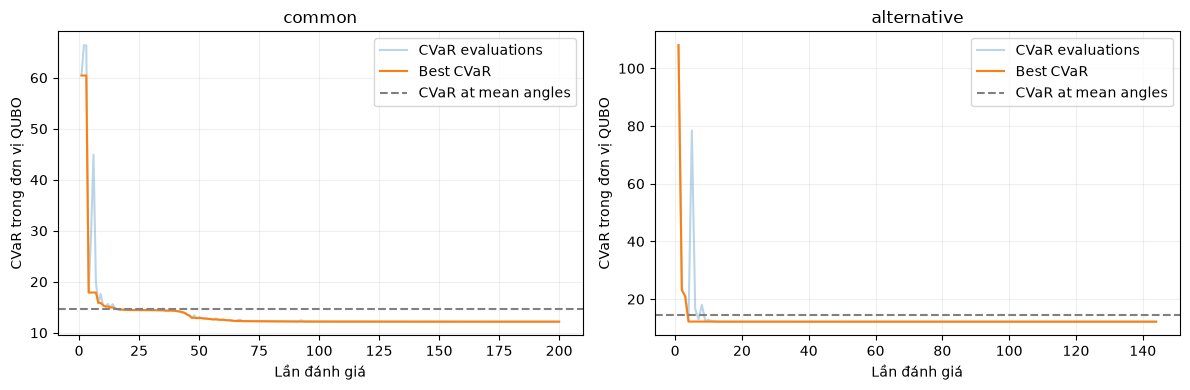

,start,best_drop_last20,final_CVaR,E_mean,stop
0,common,0.000394,12.178761,85.641334,Return from COBYLA because the objective funct...
1,alternative,0.000014,12.178013,87.532190,Return from COBYLA because the trust region ra...


In [8]:
fig,axes=plt.subplots(1,2,figsize=(12,4));tails=[]
for ax,row in zip(axes,rows):
    start=row["initial_point_id"]
    r=json.loads((ROOT/row["report"]).read_text(encoding="utf-8"))
    h=r["optimization_history"];values=np.array([v["cvar_qubo_energy"] for v in h]);best=np.minimum.accumulate(values)
    ax.plot(range(1,len(values)+1),values,alpha=.3,label="CVaR evaluations")
    ax.plot(range(1,len(values)+1),best,label="Best CVaR")
    ax.axhline(baseline_audit[start]["cvar"],color="grey",linestyle="--",label="CVaR at mean angles")
    ax.set(title=start,xlabel="Lần đánh giá",ylabel="CVaR trong đơn vị QUBO")
    ax.legend();ax.grid(alpha=.2)
    tails.append(dict(start=start,best_drop_last20=float(best[max(0,len(best)-21)]-best[-1]),
        final_CVaR=row["optimizer_objective_value"],E_mean=row["exact_mean_qubo_energy"],
        stop=row["optimizer_stop"]["message"]))
fig.tight_layout();plt.show()
display(pd.DataFrame(tails))
campaign["tail_progress"]=tails
save_campaign(MANIFEST_PATH,campaign)

## Bước 9 — Kết luận có giới hạn

- CVaR giảm, P_opt tăng ở cả hai khởi tạo: có tín hiệu tích cực trong phạm vi choice/p1; chưa chứng minh tính ổn định hoặc ưu thế tổng quát.
- CVaR giảm nhưng P_opt không tăng: tập trung vào đuôi năng lượng thấp chưa giải quyết được chỉ số placement; không tiếp tục giảm alpha tùy tiện.
- Hai khởi tạo khác nhau: báo cáo cả hai; không chỉ giữ lượt tốt hơn.
- Hết 200 đánh giá: ghi rõ chưa đạt điều kiện dừng trong ngân sách; không xem success=False là dữ liệu cần bỏ.
- Dừng số học với P_opt thấp: không suy ra cực tiểu toàn cục, barren plateau hoặc QAOA bất khả thi.

Sau đợt này, chọn một hướng có bằng chứng và giới hạn số lượt bổ sung; không tự quét alpha, tăng p hoặc thay mixer trong notebook này.

Nguồn: Barkoutsos et al., *Improving Variational Quantum Optimization using CVaR*, Quantum 4, 256 (2020): https://arxiv.org/abs/1907.04769. Alpha=0.1 là lựa chọn thử nghiệm cố định của đợt này, không phải giá trị tối ưu được bảo đảm.

In [9]:
for c in comparisons:
    print(c["start"],"| delta P_opt (điểm %):",c["delta_P_opt_pp"],"|",c["stop_cvar"])
print("Đánh giá cả CVaR, E_mean và P_opt; không chọn lại alpha theo kết quả vừa thấy.")

common | delta P_opt (điểm %): 0.026150127016838803 | Return from COBYLA because the objective function has been evaluated MAXFUN times.
alternative | delta P_opt (điểm %): 0.02444944749439204 | Return from COBYLA because the trust region radius reaches its lower bound.
Đánh giá cả CVaR, E_mean và P_opt; không chọn lại alpha theo kết quả vừa thấy.


## Bước 10 — Xác nhận và gửi kết quả
Hoàn tất nghĩa là đủ 2 report đúng thiết kế. Không bắt buộc có mẫu tối ưu hoặc chạy đủ 200 lần đánh giá.

Save As notebook có output thành `14_qaoa_cvar_choice_executed.ipynb`. Gửi notebook đó cùng ZIP được in dưới đây. ZIP chứa manifest, 2 report và CSV; dữ liệu gốc notebook 13 giữ riêng.

In [10]:
verified=verify_campaign(ROOT,campaign,design,bundle,reference)
assert len(verified)==campaign["planned_run_count"]==campaign["completed_run_count"]==2
assert not campaign["remaining_run_keys"]
assert all(r["alpha"]==.1 and r["maxiter"]==200 and r["sampling"]["evaluation_shots"]==1024 for r in verified)
EXPORT_PATH=RESULT_DIR/f"cvar_choice_{campaign['campaign_id']}.zip"
with zipfile.ZipFile(EXPORT_PATH,"w",zipfile.ZIP_DEFLATED) as z:
    for p in [MANIFEST_PATH,COMPARISON_PATH]+[ROOT/r["report"] for r in verified]:
        z.write(p,p.relative_to(ROOT).as_posix())
print("PASS — p1_choice: 2/2 exact CVaR completed, alpha=0.1, independent final sampling verified.")
print("Gửi ZIP:",EXPORT_PATH.relative_to(ROOT).as_posix())
print("Save As: 14_qaoa_cvar_choice_executed.ipynb")

PASS — p1_choice: 2/2 exact CVaR completed, alpha=0.1, independent final sampling verified.
Gửi ZIP: data/reference_results/phase4f_cvar_runs/cvar_choice_20261009T144110578365Z.zip
Save As: 14_qaoa_cvar_choice_executed.ipynb
